# pixel2dag · Notebook 01 — El DAG y la simulación de pacientes

**Objetivo:** construir un "generador de pacientes" que siga un DAG causal. Aquí todavía **no hay imágenes**; llegan en el notebook 02.

**Solo usamos:** Python básico, el módulo `random` (incluido en Python), `networkx` para el grafo y `matplotlib` para una gráfica.

**Duración:** unos 45–60 minutos.

### Cómo está organizado

Verás cuatro tipos de celda:

| Marca | Qué es | Qué haces |
|---|---|---|
| 🔍 **Ejemplo** | Código resuelto y comentado | Léelo, ejecútalo y cambia algo para ver qué pasa |
| 🤔 **Predice** | Una pregunta *antes* de ejecutar | Escribe tu respuesta en la celda y luego ejecuta para comprobarla |
| ✏️ **Ejercicio** | 1–3 líneas, casi iguales a un ejemplo anterior | Sustituye `...` por tu código |
| ✅ **Comprobación** | Te dice si vas bien | Solo ejecutar. Si falla, el mensaje te da una pista |

Ningún ejercicio usa algo que no se haya visto antes en un 🔍 Ejemplo.

---
## Parte 1 · El DAG

### La historia

Queremos simular pacientes que se hacen una foto del fondo de ojo para detectar **retinopatía diabética**.

- Cada paciente va a un **hospital** (A o B). El A es un centro de referencia y le llegan casos más graves.
- La **edad** también aumenta el riesgo.
- La **gravedad** de la enfermedad va de 0 (sano) a 4. Decimos que un paciente es **referable** (hay que derivarlo al especialista) si su gravedad es 2 o más.
- La gravedad produce **lesiones** en la retina: microaneurismas (puntitos rojos) y exudados (manchas amarillas).
- La **imagen** muestra las lesiones, pero también depende del hospital, porque cada uno tiene un escáner distinto.

### 📝 Antes de tocar código

Coge papel y dibuja el grafo: un círculo por variable (`edad`, `hospital`, `gravedad`, `n_ma`, `n_ex`, `imagen`) y una flecha de **causa → efecto** para cada frase de la historia. Cuando lo tengas, sigue.

### 🔍 Ejemplo: un grafo con `networkx`

`networkx` es una librería para trabajar con grafos. Solo necesitamos tres cosas de ella:
- `nx.DiGraph()` crea un grafo **dirigido** vacío.
- `G.add_edge("a", "b")` añade la flecha a → b. Si los nodos no existen, los crea.
- `G.edges` y `G.nodes` devuelven las flechas y los nodos.

Nodos:   ['lluvia', 'suelo_mojado', 'aspersor']
Flechas: [('lluvia', 'suelo_mojado'), ('aspersor', 'suelo_mojado')]


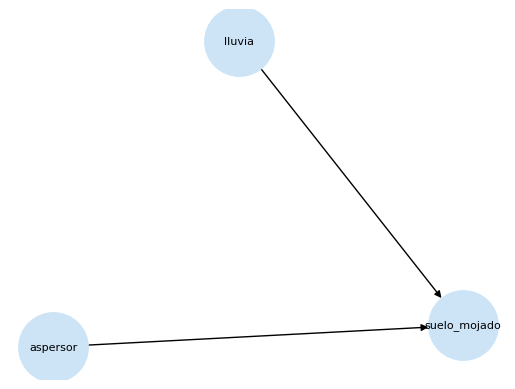

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

ejemplo = nx.DiGraph()
ejemplo.add_edge("lluvia", "suelo_mojado")
ejemplo.add_edge("aspersor", "suelo_mojado")

print("Nodos:  ", list(ejemplo.nodes))
print("Flechas:", list(ejemplo.edges))
nx.draw_networkx(ejemplo, node_color="#cde4f7", node_size=2500, font_size=8)
plt.axis("off"); plt.show()

### ✏️ Ejercicio 1.1 · Tu DAG

Crea el grafo `G` con las **7 flechas** de la historia. Debería coincidir con lo que dibujaste en papel.

In [2]:
G = nx.DiGraph()
G.add_edge("edad", "gravedad")
G.add_edge("hospital","gravedad")
G.add_edge("hospital","imagen")
G.add_edge("gravedad","n_ma")
G.add_edge("gravedad","n_ex")
G.add_edge("n_ma","imagen")
G.add_edge("n_ex","imagen")

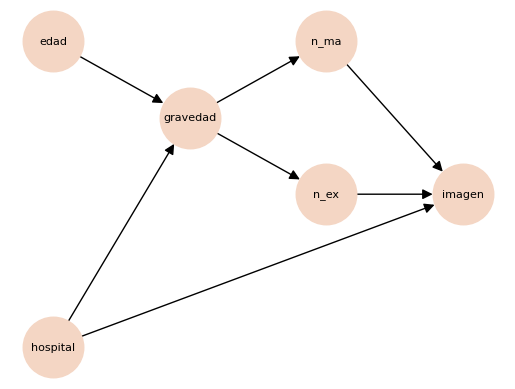

✅ ¡DAG correcto!


In [3]:
# ✅ Comprobación
esperadas = {("edad","gravedad"), ("hospital","gravedad"), ("gravedad","n_ma"), ("gravedad","n_ex"),
             ("n_ma","imagen"), ("n_ex","imagen"), ("hospital","imagen")}
faltan, sobran = esperadas - set(G.edges), set(G.edges) - esperadas
assert not faltan, f"Te faltan estas flechas: {faltan}"
assert not sobran, f"Estas flechas no están en la historia (¿o están al revés?): {sobran}"

pos = {"edad": (0, 1), "hospital": (0, -1), "gravedad": (1, 0.5),
       "n_ma": (2, 1), "n_ex": (2, 0), "imagen": (3, 0)}
nx.draw_networkx(G, pos, node_color="#f4d6c4", node_size=1900, font_size=8, arrowsize=15)
plt.axis("off"); plt.show()
print("✅ ¡DAG correcto!")

---
## Parte 2 · El azar en Python

### 🔍 Ejemplo: el módulo `random`

- `random.Random(semilla)` crea un **generador** de números aleatorios. La *semilla* es cualquier número o texto.
- `rng.random()` devuelve un número al azar entre 0 y 1.
- `rng.gauss(media, desviacion)` devuelve un número al azar de una normal.

In [13]:
import random

rng = random.Random(123)
print(rng.random(), rng.random(), rng.random())
print(rng.gauss(60, 10))

0.052363598850944326 0.08718667752263232 0.4072417636703983
76.77463938860926


### ✏️ Ejercicio 2.1 · `lanzar_monedas(rng, n, p)`

Escribe una función que lance `n` monedas con probabilidad `p` y devuelva **cuántas** salen `True`. Es casi la celda de arriba.

> 📚 **Conexión con tu asignatura de probabilidad:** el número de éxitos en `n` monedas con probabilidad `p` sigue una **Binomial(n, p)**. Y cuando `n` es grande y `p` pequeña, se parece mucho a una **Poisson** de media `n·p`. Con esta única función simularemos tanto la gravedad como las lesiones.

In [14]:
def lanzar_monedas(rng, n, p):
    res = 0
    for i in range(n):
      if(rng.random()<p):
        res+=1
    return res

In [15]:
# ✅ Comprobación
r = lanzar_monedas(random.Random(0), 10_000, 0.3)
assert r is not None, "¿Te has olvidado del return?"
assert 2850 < r < 3150, f"Con 10 000 monedas al 30 % deberían salir unas 3000; te salen {r}"
assert lanzar_monedas(random.Random(0), 50, 0.0) == 0
assert lanzar_monedas(random.Random(0), 50, 1.0) == 50
print(f"✅ Correcto: {r} éxitos de 10 000 (esperados ≈ 3000)")

✅ Correcto: 2949 éxitos de 10 000 (esperados ≈ 3000)


---
## Parte 3 · Simular cada variable

### Un dado por variable

Vamos a darle a **cada variable de cada paciente su propio generador**. Lo creamos con una semilla de texto que combina el paciente y la variable, por ejemplo `"17-edad"`.

¿Por qué no uno solo para todo? Porque más adelante querremos **cambiar una variable y que las demás no se muevan**: "este mismo paciente, pero sano". Si todas compartieran generador, cambiar una alteraría el azar de las siguientes.

In [16]:
def dado(semilla, variable):
    return random.Random(f"{semilla}-{variable}")

print(dado(17, "edad").random(), dado(17, "edad").random())   # iguales: mismo paciente y variable
print(dado(17, "edad").random(), dado(18, "edad").random())   # distintos: otro paciente

0.7804015896764286 0.7804015896764286
0.7804015896764286 0.9297426615229181


### 🔍 Ejemplo: el hospital

Es una variable **sin padres** en el DAG: solo depende del azar. La mitad de los pacientes van a cada hospital.

In [11]:
semilla = 17   # el paciente nº 17
hospital = "A" if dado(semilla, "hospital").random() < 0.5 else "B"
print("hospital:", hospital)

hospital: A


### ✏️ Ejercicio 3.1 · La edad

Tampoco tiene padres. Sigue una normal de media 60 y desviación 10. Usa `dado(semilla, "edad")` y el método `.gauss(...)` del ejemplo de la Parte 2.

In [ ]:
edad = dado(semilla, "edad").gauss(60, 10)
print("edad:", edad)

edad: 64.78688512674223


In [ ]:
# ✅ Comprobación
assert edad == dado(17, "edad").gauss(60, 10), "Usa dado(semilla, 'edad') y .gauss(60, 10)"
print("✅ Correcto")

✅ Correcto


### 🔍 Ejemplo: convertir un "riesgo" en una probabilidad

La gravedad depende de la edad y del hospital. Vamos a calcular una **puntuación de riesgo** y convertirla en una probabilidad entre 0 y 1 con la función **sigmoide**. Es la misma idea que en la regresión logística.

$$\text{riesgo} = -1 + 0.05\cdot(\text{edad} - 60) + 1.5\cdot[\text{hospital} = A] \qquad p = \frac{1}{1 + e^{-\text{riesgo}}}$$

$[\text{hospital} = A]$ vale 1 si el hospital es A y 0 si no. En Python, `(hospital == "A")` da `True` o `False`, que al multiplicarse se comportan como 1 y 0.

In [ ]:
import math

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

for x in [-4, -1, 0, 1, 4]:
    print(f"sigmoide({x:>2}) = {sigmoide(x):.3f}")

sigmoide(-4) = 0.018
sigmoide(-1) = 0.269
sigmoide( 0) = 0.500
sigmoide( 1) = 0.731
sigmoide( 4) = 0.982


### ✏️ Ejercicio 3.2 · `prob_gravedad(edad, hospital)`

Implementa la fórmula de arriba: calcula el riesgo y devuelve `sigmoide(riesgo)`. Son dos líneas.

In [ ]:
def prob_gravedad(edad, hospital):
    riesgo = -1 + 0.05 * (edad -60) + 1.5 * (hospital == "A")
    return 1/(1+math.exp(-riesgo))

In [ ]:
# ✅ Comprobación
assert isinstance(prob_gravedad(60, "B"), float), "prob_gravedad debe devolver un número (¿sigue el ... en el return?)"
assert abs(prob_gravedad(60, "B") - 0.269) < 0.001, "Revisa la fórmula para el hospital B (riesgo = -1)"
assert abs(prob_gravedad(60, "A") - 0.622) < 0.001, "Revisa el término del hospital A (+1.5)"
assert prob_gravedad(80, "B") > prob_gravedad(40, "B"), "Más edad debería dar más probabilidad"
print("✅ Correcto")

✅ Correcto


### ✏️ Ejercicio 3.3 · La gravedad

La gravedad (0–4) será el número de "pasos de empeoramiento" de **4 monedas** con probabilidad `p`. Es decir, una Binomial(4, p).

Usa `lanzar_monedas` con el dado `"gravedad"` del paciente y `p = prob_gravedad(edad, hospital)`, con la edad y el hospital que calculaste antes.

In [ ]:
p = prob_gravedad(edad, hospital)
gravedad = lanzar_monedas(dado(semilla, "gravedad"), 4, p)
print("p =", round(p, 3), "→ gravedad:", gravedad)

p = 0.677 → gravedad: 3


In [ ]:
# ✅ Comprobación
assert gravedad == lanzar_monedas(dado(17, "gravedad"), 4, prob_gravedad(edad, hospital)), \
    "Usa lanzar_monedas(dado(semilla, 'gravedad'), 4, p)"
print("✅ Correcto")

✅ Correcto


### 🔍 Ejemplo + ✏️ Ejercicio 3.4 · Las lesiones

Imagina que la retina tiene **40 sitios** donde puede aparecer un microaneurisma, y que cada sitio tiene una probabilidad que depende de la gravedad (tabla `PROB_MA`). Para los exudados hay **20 sitios** y su tabla es `PROB_EX`.

Te damos los microaneurismas hechos. Tú haz los exudados.

In [ ]:
PROB_MA = [0.0, 0.075, 0.2, 0.375, 0.625]   # gravedad 0..4 → media de 0, 3, 8, 15, 25 microaneurismas
PROB_EX = [0.0, 0.0,   0.1, 0.25,  0.5]     # gravedad 0..4 → media de 0, 0, 2, 5, 10 exudados

n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
print("microaneurismas:", n_ma)

microaneurismas: 18


In [ ]:
n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
print("exudados:", n_ex)

exudados: 4


In [ ]:
# ✅ Comprobación
assert n_ex == lanzar_monedas(dado(17, "ex"), 20, PROB_EX[gravedad]), \
    "Usa el dado 'ex', 20 sitios y PROB_EX[gravedad]"
print("✅ Correcto. Ya sabes simular todas las variables de un paciente.")

✅ Correcto. Ya sabes simular todas las variables de un paciente.


---
## Parte 4 · Juntarlo todo en una función

### Intervenciones: "¿y si forzamos una variable?"

En inferencia causal, una **intervención** $do(X = x)$ significa **forzar** una variable a un valor, ignorando sus causas. Es como si borráramos las flechas que entran en `X`.

En código lo haremos con un diccionario `do`. Si una variable aparece en él, usamos ese valor; si no, la simulamos como siempre.

### 🔍 Ejemplo: el hospital con intervención

In [ ]:
do = {"hospital": "B"}   # prueba también con do = {}

if "hospital" in do:
    hospital = do["hospital"]
else:
    hospital = "A" if dado(semilla, "hospital").random() < 0.5 else "B"
print(hospital)

B


### ✏️ Ejercicio 4.1 · `simular_paciente(semilla, do)`

Ya has escrito **cada línea** en la Parte 3. Ahora:
1. Mételas en la función, en el orden del DAG.
2. Para `edad` y `gravedad`, añade el `if ... in do` como en el ejemplo.
3. Calcula `referable` (1 si `gravedad >= 2`, si no 0).
4. Devuelve un diccionario con todo.

El hospital ya está hecho.

In [ ]:
def simular_paciente(semilla, do=None):
    if do is None:
        do = {}

    # 1. hospital
    if "hospital" in do:
        hospital = do["hospital"]
    else:
        hospital = "A" if dado(semilla, "hospital").random() < 0.5 else "B"

    # 2. edad (con if ... in do)
    if "edad" in do:
        edad = do["edad"]
    else:
        edad = dado(semilla, "edad").gauss(60, 10)

    # 3. gravedad (con if ... in do)
    if "gravedad" in do:
        gravedad = do["gravedad"]
    else:
        p = prob_gravedad(edad, hospital)
        gravedad = lanzar_monedas(dado(semilla, "gravedad"), 4, p)

    # 4. lesiones
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])

    # 5. referable
    referable = 1 if gravedad >= 2 else 0

    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": referable}

In [ ]:
# ✅ Comprobación
p17 = simular_paciente(17)
print(p17)
assert p17 == simular_paciente(17), "La misma semilla debe dar el mismo paciente"
assert p17["gravedad"] == gravedad and p17["n_ma"] == n_ma, "Debe coincidir con lo que calculaste en la Parte 3"
sano = simular_paciente(17, do={"gravedad": 0})
assert sano["n_ma"] == 0 and sano["n_ex"] == 0 and sano["referable"] == 0, \
    "Con do={'gravedad': 0} no debería haber lesiones. ¿Has puesto el if 'gravedad' in do?"
assert simular_paciente(17, do={"edad": 90})["edad"] == 90, "¿Has puesto el if 'edad' in do?"
assert sano["edad"] == p17["edad"] and sano["hospital"] == p17["hospital"], \
    "Intervenir en la gravedad no debe cambiar ni la edad ni el hospital (son sus causas, no sus efectos)"
print("✅ ¡Tu generador de pacientes funciona!")

{'semilla': 17, 'hospital': 'A', 'edad': 64.78688512674223, 'gravedad': 3, 'n_ma': 18, 'n_ex': 4, 'referable': 1}
✅ ¡Tu generador de pacientes funciona!


### 🤔 Predice: el mismo paciente con distintas gravedades

Vamos a forzar la gravedad del paciente 17 a 1, 2, 3 y 4. ¿Las lesiones irán siempre en aumento, o podrían bajar de un paso al siguiente?

<details><summary>▶ Explicación (después de ejecutar)</summary>

Nunca bajan. Cada uno de los 40 sitios tiene **siempre el mismo número al azar**, porque usa el mismo dado. Si la probabilidad sube, todos los sitios que ya tenían lesión la mantienen, y alguno más la gana. Por eso usamos un dado por variable: el paciente sigue siendo "el mismo" aunque cambiemos su gravedad. Esto es la base de los **contrafactuales**, que veremos más adelante.
</details>

In [ ]:
mi_prediccion = "..."
print("Tu predicción:", mi_prediccion)
for g in range(5):
    p = simular_paciente(17, do={"gravedad": g})
    print(f"do(gravedad={g}) → microaneurismas={p['n_ma']:>2}  exudados={p['n_ex']:>2}")

Tu predicción: ...
do(gravedad=0) → microaneurismas= 0  exudados= 0
do(gravedad=1) → microaneurismas= 3  exudados= 0
do(gravedad=2) → microaneurismas=12  exudados= 2
do(gravedad=3) → microaneurismas=18  exudados= 4
do(gravedad=4) → microaneurismas=29  exudados= 7


---
## Parte 5 · Muchos pacientes: observar frente a intervenir

### 🔍 Ejemplo: simular una población

In [ ]:
pacientes = [simular_paciente(s) for s in range(5000)]

de_A = [p for p in pacientes if p["hospital"] == "A"]
print("Pacientes del hospital A:", len(de_A))
print("Gravedad media en A:", sum(p["gravedad"] for p in de_A) / len(de_A))

Pacientes del hospital A: 2512
Gravedad media en A: 2.4832802547770703


### 🤔 Predice

¿Qué porcentaje de pacientes **referables** esperas en cada hospital? Recuerda que A recibe casos más graves.

### ✏️ Ejercicio 5.1 · Prevalencia por hospital

Calcula `prev_A` y `prev_B`: la fracción de pacientes referables en cada hospital. Sigue el patrón del ejemplo, pero sumando `p["referable"]`.

In [ ]:
de_B = [p for p in pacientes if p["hospital"] == "B"]
prev_A = sum(p["referable"] for p in de_A) / len(de_A)
prev_B = sum(p["referable"] for p in de_B) / len(de_B)
print(f"Referables en A: {prev_A:.1%}   en B: {prev_B:.1%}")

Referables en A: 81.6%   en B: 31.5%


✅ Correcto: el hospital A tiene muchos más casos referables


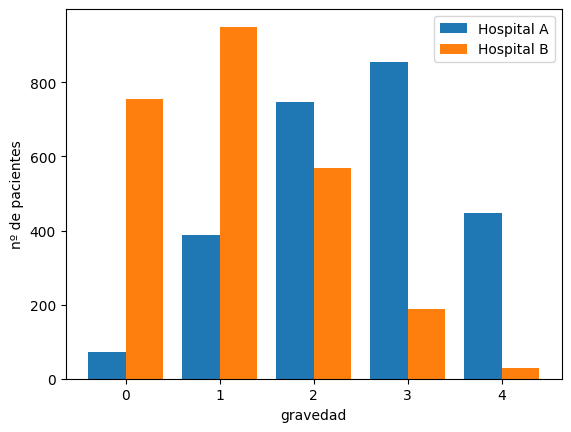

In [ ]:
# ✅ Comprobación
assert 0.75 < prev_A < 0.88 and 0.25 < prev_B < 0.38, f"Valores raros: A={prev_A:.2f}, B={prev_B:.2f}"
print("✅ Correcto: el hospital A tiene muchos más casos referables")

conteo = {h: [sum(1 for p in pacientes if p["hospital"] == h and p["gravedad"] == g) for g in range(5)] for h in "AB"}
plt.bar([g - 0.2 for g in range(5)], conteo["A"], width=0.4, label="Hospital A")
plt.bar([g + 0.2 for g in range(5)], conteo["B"], width=0.4, label="Hospital B")
plt.xlabel("gravedad"); plt.ylabel("nº de pacientes"); plt.legend(); plt.show()

### ✏️ Ejercicio 5.2 · Intervenir: $do(\text{hospital} = A)$

Ahora **mandamos a todos** los pacientes al hospital A (los mismos 5000 pacientes, con las semillas de 0 a 4999) y calculamos la fracción de referables. Es una línea para crear la lista y otra para la fracción.

In [ ]:
todos_a_A = [simular_paciente(s, do={"hospital": "A"}) for s in range(5000)]
prev_do_A = sum(p["referable"] for p in todos_a_A) / len(todos_a_A)
print(f"Observado P(referable | hospital=A)     = {prev_A:.1%}")
print(f"Intervenido P(referable | do(hospital=A)) = {prev_do_A:.1%}")

Observado P(referable | hospital=A)     = 81.6%
Intervenido P(referable | do(hospital=A)) = 81.7%


In [ ]:
# ✅ Comprobación
assert len(todos_a_A) == 5000 and all(p["hospital"] == "A" for p in todos_a_A)
assert abs(prev_do_A - prev_A) < 0.03
print("✅ Salen casi iguales")

✅ Salen casi iguales


### 🤔 Para pensar

Observar ("pacientes que **están** en A") e intervenir ("**mandar** a todos a A") han dado lo mismo. ¿Por qué? Mira el DAG: ¿tiene `hospital` alguna flecha **entrando**?

<details><summary>▶ Respuesta</summary>

No: `hospital` no tiene padres. Ninguna otra variable decide a qué hospital vas, así que los pacientes de A no son "especiales" en nada más. Por eso observar e intervenir coinciden.

Si añadiéramos la flecha `edad → hospital` (por ejemplo, porque los mayores van más al hospital A), dejarían de coincidir: los pacientes de A serían también más mayores, y parte de su gravedad se debería a la edad y no al hospital. Si quieres, pruébalo: modifica `simular_paciente` para que la probabilidad de ir a A dependa de la edad.
</details>

---
## Resumen

| Concepto | Dónde lo has usado |
|---|---|
| **DAG**: flechas de causa → efecto | Parte 1 |
| **Padres**: causas directas de una variable | `prob_gravedad(edad, hospital)` |
| **Simular en orden topológico**: primero las causas | `simular_paciente` |
| **Azar reproducible**: semilla = paciente | `dado(semilla, variable)` |
| **Binomial** como suma de monedas | gravedad y lesiones |
| **Intervención** $do(X=x)$ | el diccionario `do` |
| **Confusor**: causa común de dos variables | `hospital` → gravedad e imagen |

### Siguiente: notebook 02 · Una imagen es una matriz de números

Aprenderás `numpy` desde cero (lo justo) para dibujar el fondo de ojo y las lesiones de cada paciente. Al final, `simular_paciente(17)` tendrá cara.